## GRG 356T Spatial Data Science and Maps
### The University of Texas at Austin, Department of Geography and the Environment
Developed by Yuhao Kang (instructor), Xihan Yao and Brody Manquen. Part of *Responsible GeoAI for Civic Futures*, supported by the Mozilla Foundation.


# Lab 3: Geocoding and Web Scraping

## <b>Section 1: HTTP Requests with `requests` package</b>

Goal: cover the basics of web requests, the foundations for geocoding & web scraping.

HTTP Request: a message sent from a client to a server asking for a specific resource.

The main element of a HTTP request is the Request-Line, which is comprised of the following:
- Method: GET (retrieve info from server); POST (send data to server)...(there are several more, but these are very common)
- Request-URI: Uniform Resource Identifier (the identifier of the resource you want from the server, e.g., image, webpage, etc.)
- Request Headers: optional modifier to the request (ex: "Accept-Language: en-us" modifies a request to only accept resources in English)

We will cover the GET and POST methods for some simple HTTP requests

More information about the `requests` package can be found here: https://requests.readthedocs.io/en/latest/api/

## Setup

Run the cell below **first**. It checks that every package this lab needs is
installed, and installs anything that is missing.

If it installs something, restart and run the cell again — that is
**Kernel > Restart** in Jupyter, or **Runtime > Restart session** in Google
Colab. The cell prints whichever one applies to you.

*Working in Colab?* You get a fresh machine every session, so this cell will
install packages **every time** you open the lab. That is normal — let it run.


In [ ]:
# =====================================================================
# Lab 3 -- Setup: check that every package this lab needs is installed
# AND new enough. Run this cell FIRST. It is safe to re-run.
# =====================================================================

import importlib.metadata as md
import subprocess, sys

# pip package name -> minimum version this lab was written against
REQUIRED = {
    "beautifulsoup4": "4.12",
    "requests":       "2.31",
    "pillow":         "10.0",
    "leafmap":        "0.30",
    "ipyleaflet":     "0.19",
    "ipywidgets":     "8.0",
    "matplotlib":     "3.8",
    "pandas":         "2.2",
    "geopandas":      "1.0",
}


def version_tuple(text):
    """'1.10.2' -> (1, 10, 2), so 1.10 correctly counts as newer than 1.9."""
    parts = []
    for piece in text.split(".")[:3]:
        digits = "".join(ch for ch in piece if ch.isdigit())
        parts.append(int(digits) if digits else 0)
    return tuple(parts)


problems = []
for package, minimum in REQUIRED.items():
    try:
        installed = md.version(package)
    except md.PackageNotFoundError:
        problems.append((package, minimum, "not installed"))
        continue
    if version_tuple(installed) < version_tuple(minimum):
        problems.append((package, minimum, "you have " + installed))

if problems:
    print("Installing or upgrading " + str(len(problems)) + " package(s):")
    for package, minimum, why in problems:
        print("   " + package + "  (needs >=" + minimum + ", " + why + ")")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade",
                           *[p + ">=" + m for p, m, _ in problems]])
    print("\nInstall finished.")
    if "google.colab" in sys.modules:
        print(">>> Now use the menu:  Runtime > Restart session,  then run this cell again. <<<")
        print("    Colab hands you a fresh machine every session, so this install will")
        print("    happen every time you open the lab. That is expected, not an error.")
    else:
        print(">>> RESTART THE KERNEL now, then run this cell again to confirm. <<<")
else:
    print("All " + str(len(REQUIRED)) + " required packages are present and new enough.")
    for package in REQUIRED:
        print("   " + package.ljust(18) + md.version(package))

### Imports

Every package this lab uses is imported here, once, with a note on what it is for.


In [ ]:
# =====================================================================
# Lab 3 -- Every import this notebook needs, in one place.
# Run this cell right after the Setup cell above. Later cells assume
# these names already exist, so re-run it after any kernel restart.
# =====================================================================

# --- HTTP requests and API responses ---
import requests                           # GET / POST calls: Wayback Machine, Google APIs, Redfin
import json                               # parse the Geocoding API's JSON reply into a Python dict
import getpass                            # type your Google API key in without it showing on screen

# --- files, paths, and connections ---
import os                                 # build the Exercise folders and file paths for saved output
import io                                 # wrap raw Street View bytes so Pillow can open them
import time                               # pause between retries when a site rate-limits us
import ssl                                # HTTPS/TLS layer under the requests calls (kept from Sec. 2)
import pathlib                            # build the api_cache folder that saves you repeat API calls
import hashlib                            # give each cached API request a short, stable filename

# --- images and plotting ---
from PIL import Image                     # open and save the downloaded Street View JPEG
import matplotlib.pyplot as plt           # show the Street View image inline
import matplotlib.patches as mpatches     # optional shapes drawn on top of an image plot

# --- interactive / satellite maps ---
# leafmap reads GOOGLE_MAPS_API_KEY from your environment and, if it finds one,
# tries to open a Google *Tile* API session. A key without the
# Tile API, so that turns this import into a wall of 403 JSON. Clearing the
# variable first makes leafmap fall back to the free Esri basemap this lab uses.
os.environ.pop("GOOGLE_MAPS_API_KEY", None)
import leafmap                            # Esri satellite basemap centered on the geocoded point
import ipyleaflet                         # map engine that leafmap is built on
import ipywidgets                         # lets the leafmap map render inside Jupyter

# --- tables and geodata (Exercise 3) ---
import pandas as pd                        # build the rental table before writing it to .csv
import geopandas as gpd                    # turn that table into a GeoDataFrame of points

# --- web scraping ---
from bs4 import BeautifulSoup             # parse the Redfin HTML, pull out address / rent tags

### GET

In [ ]:
## Let's say that we're curious about mining text from the earliest archived Wikipedia page for Austin

### The WaybackMachine is a tool on web.archive.org that has archived versions of web pages

### The earlist Wikipedia page for Austin on the archive is from July 1st, 2004.
 
url = "https://web.archive.org/web/20040701082448/https://en.wikipedia.org/wiki/Austin,_Texas"
# Send a request to a website
response = requests.get(url)

print("Status Code:", response.status_code)

More about status codes can be found here: https://en.wikipedia.org/wiki/List_of_HTTP_status_codes

`200` is what we're looking for! It means the request got through ok.

If we had just requested https://en.wikipedia.org/wiki/Austin,_Texas you would get `403`, <b>Forbidden</b> because Wikipedia has protections against automated access (commonly used by bots).

#### Headers
Headers contain the 'building blocks' of the request/response. When you print the headers, you'll see a complex dictionary that look like this: {header type: header content}

For example: {`Content-Type`:`text/html`} tells us that the response to our request is a Text/HTML file.

Headers define how requests are processed, including the format, authentication context, caching behavior, and other related details. For this lab, we are requesting a simple webpage. However, some data may be restricted or only accessible with specific HTTPS requests. An `API` is essentially a specific HTTPS request that has the right headers to access the data. 

For example, you cannot simply use `requests` on Google StreetView imagery, you need an API to send the correct request for you. 

In [ ]:
print("Headers:", response.headers)

In [ ]:
print(response.headers["Content-Type"])

#### Response Text

There are many applications for such requests/responses. Here, we'll focus on extracting information from the text of a website.

Our response to the archived Wikipedia page has text built into it. We can directly access and use this data.

The data is stored in HTML. Each <> (like `<p>` or `<strong>`) is called a `tag`. Tags might describe section breaks, or make the letters <b>bold</b> or <i>italicized</i>. But they also might contain links (`<href>`). These markdown cells are written, partially, with HTML tags.

Point being, HTML tags turn a wall of text into a readable, aesthetically pleasing website.

More info here: https://www.w3schools.com/html/html_intro.asp

In [ ]:
## Let's print the first block of text from the 2004 Wikipedia page
## We can see that there are links to other Wikipedia articles (like the one for "Capital") and text in different codes.
print(response.text[3923:10000])

#### Opening and Saving Files
Our `requests` response is pretty messy. Therefore, we'll use `open()` and `.write()` to first create an object (our file path), then write the contents of our response to that file path.

`open()` essentially creates a file object with our file path & the mode (i.e., read mode, write mode, etc.). More info here: https://docs.python.org/3/library/functions.html#open

`.write()` is a method that writes specified text to a file (https://www.w3schools.com/python/ref_file_write.asp)

In [ ]:
# Save the responsive text as an html file -- you can find this in your folder in the left panel

## with open(file, mode) as [[[variable]]] sets the file path as an object to be manipulated
with open('wikipedia_austin2004.html', 'w') as html_file:
    ## .write(response.text) takes our response text and writes it into the file.
    html_file.write(response.text)

#### Binary Mode

The previous HTML was only written with `w` mode, which is for text only.

Sometimes, we need to save other types of data -- so instead of `w` we use `wb`

The `b` stands for "binary" and it lets us preserve all machine-readable information, such as images.

Let's see this in practice using a painting at the Art Institute of Chicago, "The Old Temple" by Hubert Robert (1787/8):
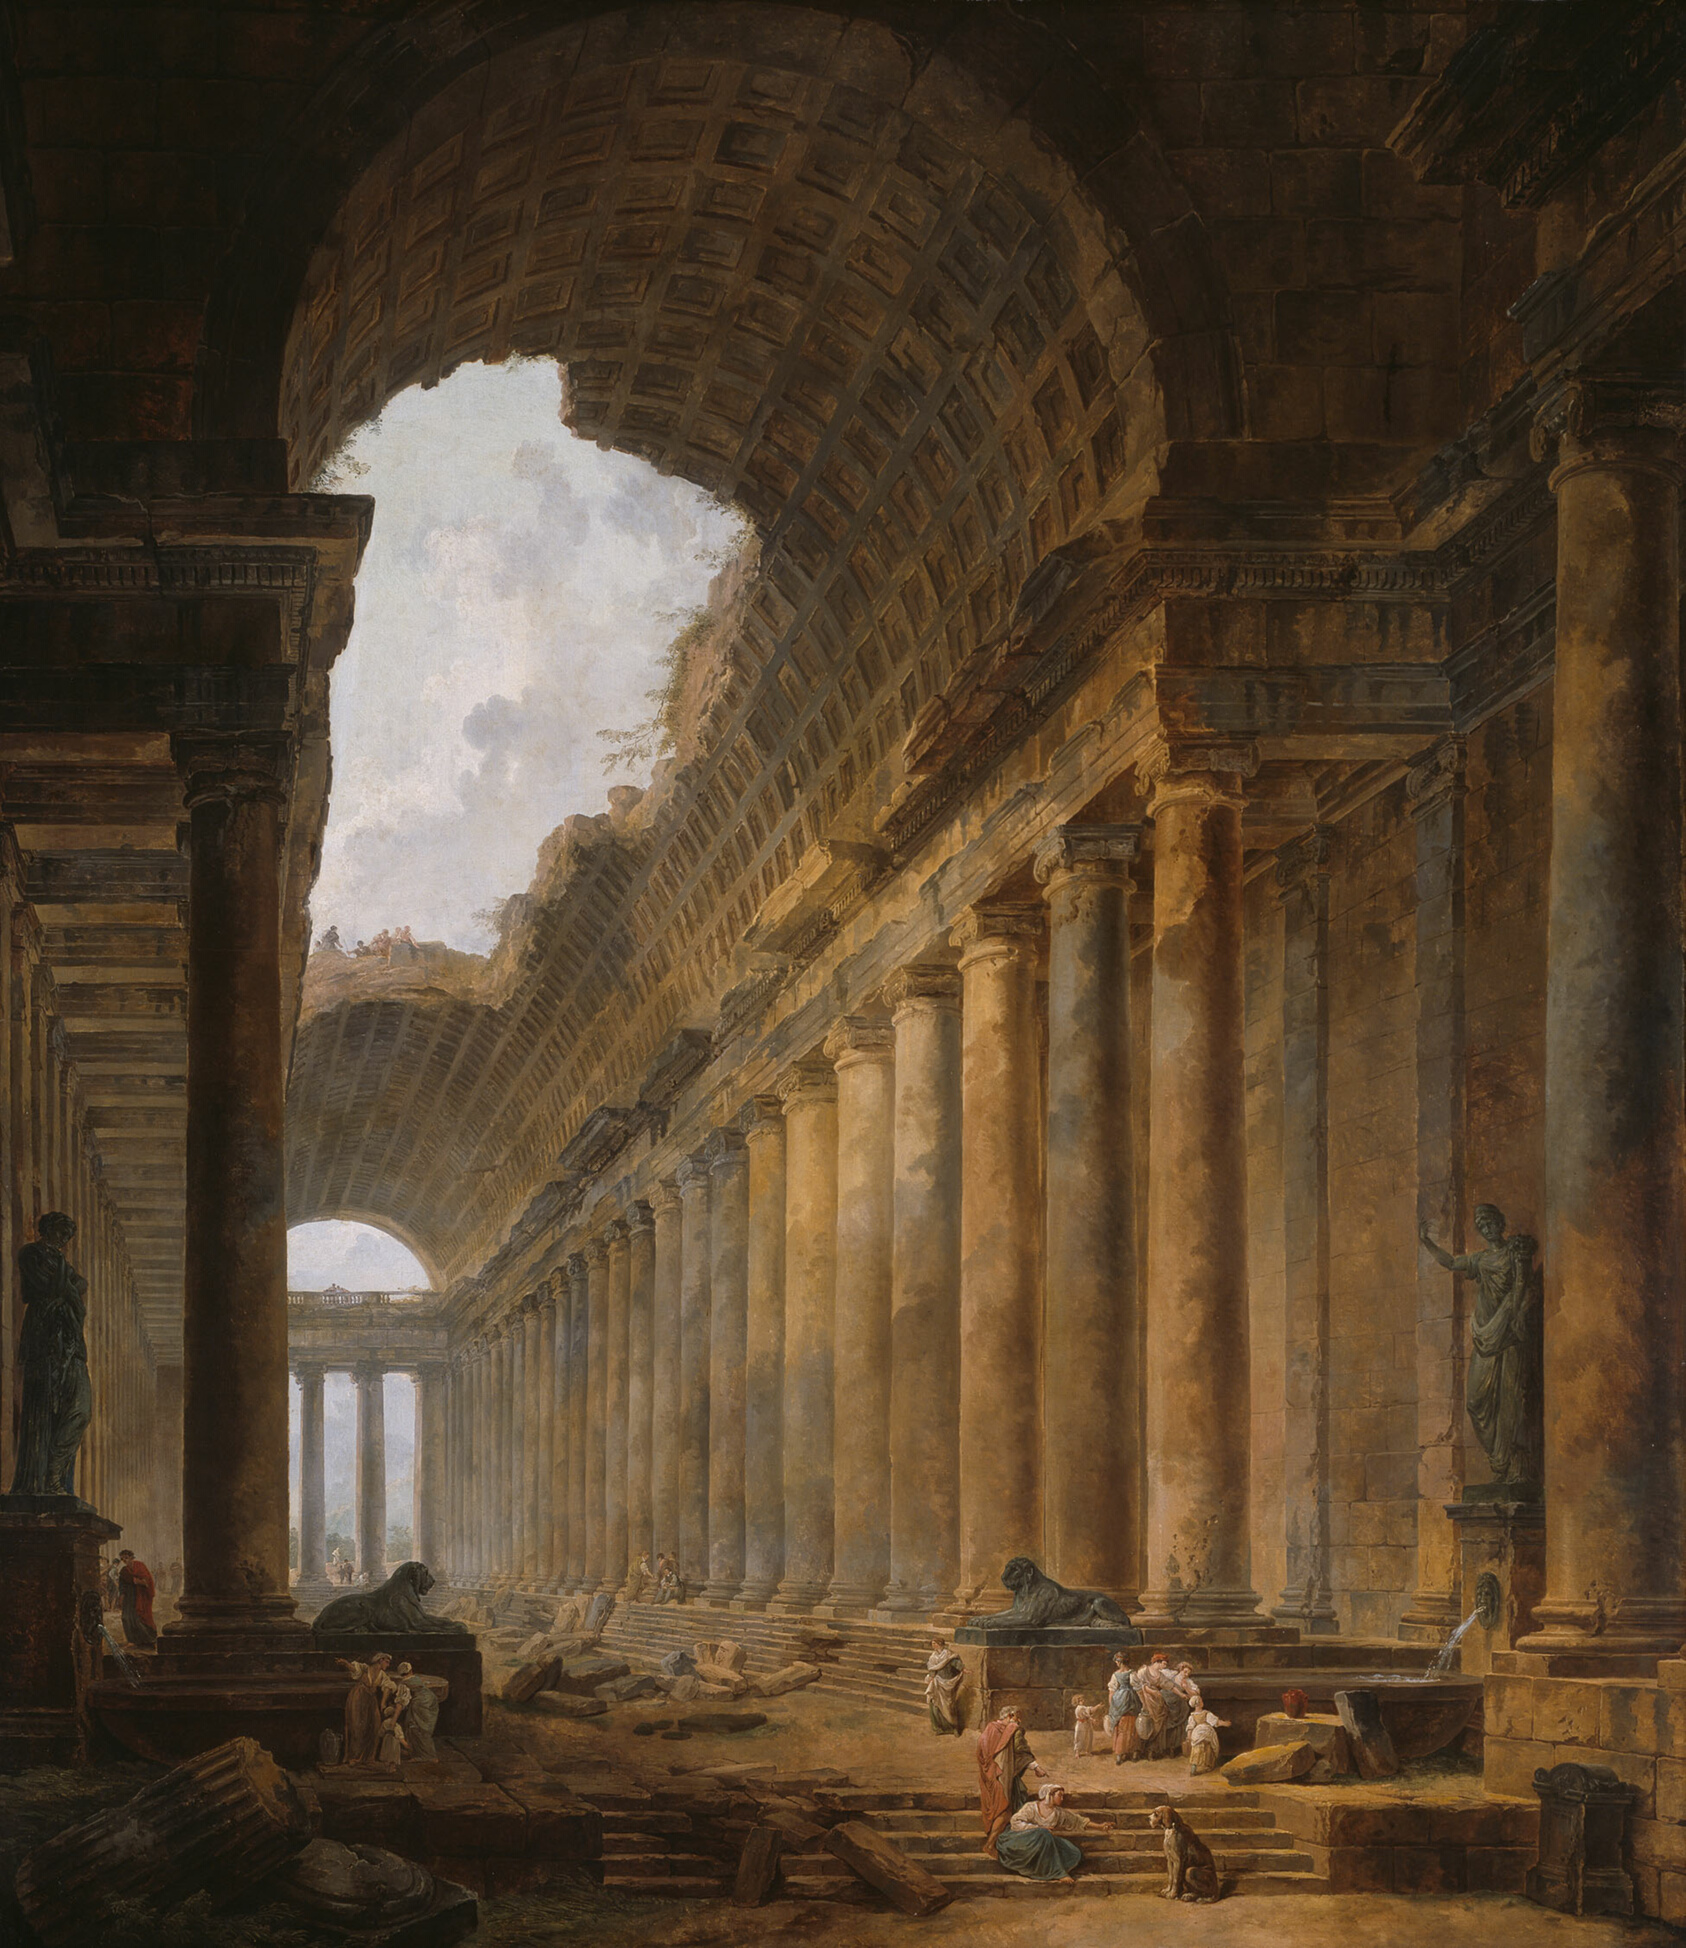

In [ ]:
# We can get the image's URL as normal -- but with one addition.
#
# The museum's server refuses requests that do not look like they came from a
# web browser. Without the header below it answers 403 Forbidden and sends back
# an error page instead of the painting, and the next two cells then quietly
# save that error page as a broken .jpg.
#
# 'User-Agent' is the header every browser sends to introduce itself. Copying a
# browser's value is how we ask to be treated like one. This is the same trick
# Section 3 needs to read Redfin.

headers = {'User-Agent': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) '
                         'AppleWebKit/537.36 (KHTML, like Gecko) '
                         'Chrome/120.0.0.0 Safari/537.36'}

response = requests.get(
    url='https://www.artic.edu/iiif/2/00fdacbb-872a-1091-3272-39967374ec07/full/1686,/0/default.jpg',
    headers=headers)

print("Status:", response.status_code, "|", len(response.content), "bytes")

> ### ⚠️ The next cell is SUPPOSED to fail. That is the lesson, not a bug.
>
> It deliberately uses text mode (`w`) to write image **bytes**, so Python raises:
>
> ```
> TypeError: write() argument must be str, not bytes
> ```
>
> **Nothing is broken and there is nothing for you to fix.** Read the error, then
> run the cell after it — the only difference is `w` → `wb`. Seeing this error
> once is how you will remember the difference.


In [ ]:
# =====================================================================
# EXPECTED TO FAIL -- see the note above. Do not try to fix this cell.
#
# 'w' opens the file in TEXT mode, but response.content is BYTES, so Python
# refuses with: TypeError: write() argument must be str, not bytes
#
# Read that error, then run the next cell, which uses 'wb' instead.
# =====================================================================
with open('oldtemple_img.jpg', 'w') as img:
    img.write(response.content)

In [ ]:
## Changing "w" to "wb" tells Python to write as 'binary'.
## binary -- unlike the plain text writing -- preserves images
with open('oldtemple_img.jpg', 'wb') as img:
    img.write(response.content)

#### Parameters

Parameters are `query` options in a request. Parameters are often called the `payload`, and are stored as a dictionary.

For example, when we Google something, we are really going to the website `www.google.com/search` and adding some query parameters.

If we want to search "Austin geology" -- say you realize that you don't know much about the rock you're living on top of, and that bothers you -- we are really just adding `?q=austin+tx+geology` to our URL.

As a parameter dictionary, that looks like this: `payload = {"q":"austin tx geology"}`

`q` = our query key

`austin tx geology` = our value associated with our key.

In [ ]:
#To translate this into Python
url = "https://www.google.com/search"
# Send a request with parameters
payload = {
    "q": "austin tx geology" # you can replace this with anything you'd like to search!
}
response = requests.get(url=url, params=payload)
print("Click here!: ", response.url)

with open('google_q.html', 'w') as html_file:
    html_file.write(response.text)

### POST

The `POST` method for our requests sends data to a server, the opposite of a `GET`.

In [ ]:
# Send a post to a website
# https://httpbin.org/post -- a test server that simply echoes back whatever we send it
data = {
    "custname": "Jane Doe",
    "custtel": "555-0100",
    "custemail": "jane.doe@example.com",
    "diss_topic": "Urban Heat Islands",
    "current_hobby": "hiking",
    "current_book": "The Power Broker"
}
## convert the file to a .json for us to look at here
with requests.post('https://httpbin.org/post', data = data) as response:
    with open('posts.json', 'wb') as post_json:
        post_json.write(response.content)

In [ ]:
# Send a "login" with POST
### POST is also how a login form sends your username and password.
### httpbin.org/post is a test server: it echoes the form back instead of logging anyone in.
### Never put a real username or password in a notebook.

headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/41.0.2228.0 Safari/537.36'}
info = {
    "username": "demo_user",
    "password": "not_a_real_password"
}

with requests.post('https://httpbin.org/post', data=info, headers=headers) as response:
    with open('login_demo.json', 'wb') as login_file:
        login_file.write(response.content)

## A real site would check these against its records and send back a session cookie.

### <b>Exercise 1:</b> 

Say we want to collect weather data from Weather Underground (https://www.wunderground.com/) for five Texan cities: Houston, Dallas, Austin, San Antonio, and El Paso.

Create (1) a list of each city (city_list) and (2) use a <b>for loop</b> to GET the URL of that city's current weather. Save the HTML for each city in a `Exercise1_HTML` folder.

Look at how the website creates URLs:
- Waco: https://www.wunderground.com/forecast/us/tx/waco
- Round Rock: https://www.wunderground.com/forecast/us/tx/round-rock

You'll want to revisit how to use <b>f-strings</b> to plug your list values into the for-loop

In [ ]:
# =====================================================================
# STEP 0 -- OUTPUT FOLDER AND SAVE HELPER.  Written for you. Just run it.
#
# The exercise is about building the city list, the URLs (f-strings) and the
# for loop. Creating a folder and writing text to disk is not the point, so
# that part is done here.
# =====================================================================

os.makedirs("Exercise1_HTML", exist_ok=True)
print("created Exercise1_HTML/")


def save_html(html_text, city_name, folder="Exercise1_HTML"):
    """Write one page's HTML into the folder, named after the city."""
    filename = city_name.lower().replace(" ", "-") + ".html"
    path = os.path.join(folder, filename)
    with open(path, "w", encoding="utf-8") as f:
        f.write(html_text)
    print(f"  saved {path}  ({len(html_text):,} characters)")


# So inside your loop you only need to do:
#     r = requests.get(url)
#     save_html(r.text, city)

In [ ]:
## Exercise 1 here


## <b>Section 2: Geocoding with Google API</b>

Goal: Use Google Maps API for geocoding & Street View Imagery collection.

Geocoding: process of taking a text-based description of a location, such as an address or the name of a place, and returning geographic coordinates

### Your Google API key

Section 2 and Exercises 2 and 3 use two Google Maps Platform services: the
**Geocoding API** (address to coordinates) and the **Street View Static API**
(coordinates to photograph).

You need a Google Maps Platform API key with both services enabled. Create one at
https://console.cloud.google.com/google/maps-apis . Google asks for a billing account;
check Google's current pricing and free monthly usage before you start. If you are taking
this lab in a class, your instructor may give you a key instead.

Paste the key into the prompt in the next cell. It is held in memory for your session
only -- it is never written into this notebook, so it cannot end up in a file you share.

**Three things to know:**

1. Do not paste the key into a code cell, a screenshot, a chat, or anything you hand in.
   Always use the prompt.
2. This notebook caches every API result to disk. Re-running a cell to fix a typo costs
   nothing, so re-run as often as you like.
3. There is a call budget that stops the notebook if it tries to make far more requests
   than this lab needs. If you hit it, you almost certainly have a loop nested inside
   another loop. Fix the loop rather than raising the budget.


In [ ]:
# Paste your Google API key when the prompt appears below.
# Nothing will appear as you type or paste -- that is deliberate, so your key
# is never saved into this notebook or visible on a shared screen.

api_key = getpass.getpass("Paste your Google API key, then press Enter: ").strip()

if not api_key:
    print("No key entered. Re-run this cell and paste your key.")
    print("The cells below cannot work without it.")
elif not api_key.startswith("AIza"):
    print("Hmm -- Google API keys normally start with 'AIza'.")
    print("Re-run this cell and double-check what you pasted.")
else:
    print("Key received (" + str(len(api_key)) + " characters).")
    print("It is held for this session only, and disappears when the kernel restarts.")


### Geocoding with Google API

Geocoding is the process of converting an address or place name into coordinates & geospatial information in code.

Google's `Geocode API` is a very quick way to do this. You simply pass an address into the API as a URL, and get a result.

https://maps.googleapis.com/maps/api/geocode/json?address=304+E+44th+St,+Austin,+TX&key=YOUR_KEY

First, notice the `maps/api/geocode/json` portion of the URL. This is telling us that we are using the Geocode API & that we are getting our response as a JSON file.

Second, our query (everything after ?) adds the following to the URL:

`address`: the location we want to geocode using a street addresss.

`key`: the API key telling the server that we have authorization from Google to access this data.

More information address requests with the Geocoding API can be found here: https://developers.google.com/maps/documentation/geocoding/requests-geocoding

#### <b>Let's look at the Elisabet Ney Museum, a little sculpture museum in the Hyde Park neighborhood of Austin.</b>

In [ ]:
# Set the parameters of the request
params = {
    "address": u"333 E 44th St, Austin, TX", ## the "u" sets the address to Unicode, which helps it read potentially difficult characters
    ## if you change the address to "330" you'll get some statue busts
    "key": api_key,
    "lang": "en" ## language defaults to English, but included to show that other options are possible
}
response = requests.get(url="https://maps.googleapis.com/maps/api/geocode/json", params=params)

In [ ]:
print("HTTP status:", response.status_code)

# Google can return an API error even when the HTTP status is 200.
result = response.json()
print("Geocoding status:", result.get("status"))

In [ ]:
# Read the Data as a JSON
data = response.text
print(json.loads(data)) ## you can see there's a lot of geospatial information

In [ ]:
## There's a lot of nested lists, so we need to do a lot of subsetting to get the data
### Here is the Geometry dictionary nested within the Results list
print(json.loads(data)["results"][0]["geometry"])

In [ ]:
print("Coordinates of Elisabet Ney Museum in Austin, TX:", json.loads(data)["results"][0]["geometry"]["location"])

In [ ]:
##save your results as variables
lat= json.loads(data)["results"][0]["geometry"]["location"]['lat']
lon= json.loads(data)["results"][0]["geometry"]["location"]['lng']

In [ ]:
print(lat, lon)

### Street View Imagery with Google API

Google Maps also stores street view imagery that is often desirable for geospatial analyses. We'll start with downloading individual images, but later in the course we will explore batch downloads.

Make sure your key has the **Street View Static API** enabled at https://console.cloud.google.com/apis/dashboard .

StreetView imagery uses the `StreetView` API, which should be accessible using the same API key. 

Detailed information about this API can be found here: https://developers.google.com/maps/documentation/streetview/overview

#### Before we build the Street View function: protecting a shared key

Everyone in this class is using the same API key, which means the quota is
shared too. The cell below sets up two safeguards that the rest of the lab uses.

**A cache.** Every request is saved to an `api_cache` folder. If you ask for the
same address or the same photograph twice, the second one is read from disk and
costs nothing. Debugging a loop no longer burns quota.

**A call budget.** If the notebook tries to make far more requests than this lab
needs, it stops itself with an explanation. A clean run of Lab 3 makes about 40
calls, so anything approaching 150 means something is wrong with a loop.

Caching API results is not just a classroom rule -- it is ordinary practice
whenever you work against a paid or rate-limited API.

**If the class does run out of quota, you will be told so plainly.** The helper
functions below read Google's reply and separate two things that look identical
otherwise: *"I could not find that address"* (your loop skips it and carries on)
and *"the class is out of API calls"* (your loop stops, with instructions). You
will never be left staring at a column of `None` wondering which one happened.

In [ ]:
# =====================================================================
# Lab 3 -- shared-key protection: an on-disk cache and a runaway-loop guard.
#
#   CACHE -- a request you have already made is read back from disk, so
#            re-running a cell to fix a typo costs nothing.
#   GUARD -- the notebook stops itself if it tries to make far more calls
#            than this lab needs. That is nearly always a nested loop.
#
# Run this cell once. Please do not raise CALL_BUDGET.
# =====================================================================

CACHE_DIR = pathlib.Path("api_cache")
CACHE_DIR.mkdir(exist_ok=True)

CALL_BUDGET = 150        # a clean full run of this lab needs about 40
_calls_made = 0


def api_get(url, params, kind, binary=False, validate=None):
    """GET a URL, but reuse a saved reply when we already have one.

    kind      -- short label so different request types get separate cache files
    binary    -- True for images, False for JSON/text
    validate  -- optional test; only replies that pass it are written to the cache,
                 so a failed lookup is never remembered as if it had worked
    """
    global _calls_made

    # Build a stable filename from the parameters, leaving the key out of it.
    stable = json.dumps({k: v for k, v in params.items() if k != "key"}, sort_keys=True)
    path = CACHE_DIR / (kind + "_" + hashlib.md5(stable.encode()).hexdigest())

    if path.exists():                      # already fetched -- free
        return path.read_bytes() if binary else path.read_text(encoding="utf-8")

    if _calls_made >= CALL_BUDGET:
        raise RuntimeError(
            "STOPPED at " + str(_calls_made) + " API calls -- over the "
            + str(CALL_BUDGET) + "-call budget for Lab 3.\n"
            "A clean run needs about 40, so this is almost certainly a loop "
            "nested inside another loop. Check your Exercise 3 code, restart "
            "the kernel, and run again.\n"
            "Ask your TA before changing CALL_BUDGET -- the whole class shares "
            "one key, and this quota is your classmates' too."
        )

    reply = requests.get(url=url, params=params)
    _calls_made += 1
    payload = reply.content if binary else reply.text

    if validate is None or validate(payload):
        if binary:
            path.write_bytes(payload)
        else:
            path.write_text(payload, encoding="utf-8")

    return payload


def calls_used():
    """Print how much of the budget this session has spent."""
    print("API calls this session: " + str(_calls_made) + " of " + str(CALL_BUDGET))
    print("(results read back from the cache are free and are not counted)")


print("Cache ready at ./api_cache -- re-running cells below is free.")
print("Call budget: " + str(CALL_BUDGET) + " requests per session.")

In [ ]:
# Two helper functions built on api_get() above. Use these for Exercises 2 and 3.
#
# They also translate Google's status codes into plain English. That matters,
# because Google reports "I could not find that address" and "the class has run
# out of API quota" through the same channel -- and those two need completely
# different reactions from you.


class QuotaStop(RuntimeError):
    """Raised when the key is out of quota or Google rejected it.

    This stops your loop on purpose. It is not a bug in your code.
    """


# "this one address is bad -- skip it and carry on with the rest"
SOFT_FAIL = {"ZERO_RESULTS", "NOT_FOUND", "INVALID_REQUEST"}

# "no further calls will work for anyone until something changes"
HARD_FAIL = {"OVER_QUERY_LIMIT", "OVER_DAILY_LIMIT", "REQUEST_DENIED"}


def _stop_message(status, service):
    """Build the explanation a student actually needs when a request is refused."""
    rule = "=" * 68

    if status == "REQUEST_DENIED":
        return ("\n" + rule
            + "\n  GOOGLE REJECTED THE API KEY. Your code is fine.\n" + rule
            + "\n\n" + service + " answered: REQUEST_DENIED"
            + "\n\nWhat to do, in order:"
            + "\n  1. Re-run the cell where you pasted the key. By far the most"
            + "\n     common causes are a key copied with a stray space on the"
            + "\n     end, or a kernel restart that cleared it from memory."
            + "\n  2. Check you copied the whole key."
            + "\n  3. If it still fails, message your TA. The key may need to be"
            + "\n     reissued, which is not something you can fix from here.\n")

    return ("\n" + rule
        + "\n  THE CLASS API QUOTA IS USED UP FOR NOW."
        + "\n  This is not your fault and it is not a bug in your code.\n" + rule
        + "\n\n" + service + " answered: " + status
        + "\n\nEveryone in this class shares one API key, so the daily allowance"
        + "\nis shared too. It has been used up for today."
        + "\n\nWhat to do, in order:"
        + "\n  1. Wait about a minute, then re-run this cell. Short bursts trip a"
        + "\n     per-minute limit that clears on its own."
        + "\n  2. If it still fails, today's allowance is gone. YOUR WORK IS NOT"
        + "\n     LOST. Every result you already fetched is saved in the"
        + "\n     api_cache folder. Re-run tomorrow and the notebook picks up"
        + "\n     exactly where it stopped, without re-spending those calls."
        + "\n  3. If you are in a class, tell your instructor. If the deadline is close, say"
        + "\n     so -- the limit can be raised."
        + "\n\nPlease do NOT:"
        + "\n  - delete the api_cache folder. That throws away your progress and"
        + "\n    makes tomorrow's re-run cost full price again."
        + "\n  - raise CALL_BUDGET. That spends your classmates' quota."
        + "\n  - paste in some other API key you found online.\n")


def geocode(address):
    """Turn an address into (lat, lon). Returns (None, None) if Google has no match.

    Raises QuotaStop if the key is out of quota, so that a loop stops
    loudly instead of quietly filling your table with None.
    """
    text = api_get(
        url="https://maps.googleapis.com/maps/api/geocode/json",
        params={"address": address, "key": api_key, "lang": "en"},
        kind="geocode",
        validate=lambda t: json.loads(t).get("status") == "OK",
    )
    reply = json.loads(text)
    status = reply.get("status", "UNKNOWN_ERROR")

    if status == "OK":
        spot = reply["results"][0]["geometry"]["location"]
        return spot["lat"], spot["lng"]

    if status in HARD_FAIL:
        raise QuotaStop(_stop_message(status, "The Geocoding API"))

    if status in SOFT_FAIL:
        print("  no match for " + repr(address) + "  (" + status + ") -- skipping")
    else:
        print("  temporary problem on " + repr(address) + "  (" + status + ")"
              + " -- re-run this cell to try it again")
    return None, None


def download_sv_latlng(lat, lng, img_path, size="400x400", heading="45", pitch="0"):
    """Download a Street View image for a coordinate and save it to img_path.

    Important: when Google has no photograph of a location, the Street View API
    does NOT return an error. It returns a grey "Sorry, we have no imagery here"
    picture with a perfectly normal 200 status. So we ask the metadata endpoint
    first, and only spend an image request when coverage really exists.
    """
    meta = json.loads(api_get(
        url="https://maps.googleapis.com/maps/api/streetview/metadata",
        params={"location": f"{lat}, {lng}", "key": api_key},
        kind="svmeta",
        validate=lambda t: json.loads(t).get("status") in ("OK", "ZERO_RESULTS"),
    ))
    status = meta.get("status", "UNKNOWN_ERROR")

    if status in HARD_FAIL:
        raise QuotaStop(_stop_message(status, "The Street View metadata service"))

    if status != "OK":
        print("  no Street View coverage at " + str(lat) + ", " + str(lng)
              + "  (" + status + ") -- skipping")
        return None

    raw = api_get(
        url="https://maps.googleapis.com/maps/api/streetview",
        params={"size": size, "location": f"{lat}, {lng}", "heading": heading,
                "pitch": pitch, "key": api_key},
        kind="sv",
        binary=True,
        validate=lambda b: b[:3] == b"\xff\xd8\xff",   # a real JPEG starts with this
    )

    # Street View images and Street View metadata are billed as two separate
    # services with two separate allowances, so the image request can be refused
    # even though the metadata request just succeeded.
    if raw[:3] != b"\xff\xd8\xff":
        raise QuotaStop(_stop_message("OVER_QUERY_LIMIT",
                                      "The Street View Static API"))

    img = Image.open(io.BytesIO(raw))
    img.save(f"{img_path}")
    return img

In [ ]:
# Download a single street view image at the intersection near the Elisabet Ney Museum

## Remember that we saved our lat/lon information from earlier

sv_img = download_sv_latlng(lat, lon, "elisabet_ney_sv.jpg")

In [ ]:
# Display the street view image we just downloaded
if sv_img is None:
    print("Nothing to show -- there is no Street View coverage at that point.")
else:
    plt.imshow(sv_img)
    plt.axis('off')  # Turn off axis numbers and ticks
    plt.title('Street View Image')
    plt.show()

### Remote Sensing Image from Leafmap
Leafmap is a lightweight Python package that allows us to grab satellite imagery for a location. Let's continue with the Elisabet Ney Museum.

More on Leafmap here: https://leafmap.org/

In [ ]:
# Create a map centered on the coordinates
m = leafmap.Map(center=(lat, lon), zoom=20)
# Add a high-resolution basemap (Esri satellite imagery)
m.add_basemap('Esri.WorldImagery')
# You can open the .html in a new tab within JupyterLab and hit "Trust HTML" in the top left
m.to_html('rs_image.html') 

In [ ]:
# Colab -- you can just display it natively within Colab
m

### <b>Exercise 2:</b>

Manually geocode your three favorite restaurants by converting their address to lat, lon coordinates with your Google API.

Using the previous scripts, find a StreetView Image & zoom to the Remote Sensing location of each restaurant.

Download the image & save the HTML of the RS location to a `Exercise2_Images` folder. Use <b>f-strings</b> to name each image/html after the input address.

<b>Use the `geocode()` and `download_sv_latlng()` helpers defined above</b> rather than writing the requests by hand again. They cache their results, so you can re-run this as many times as you need while you get the file naming right.

In [ ]:
# =====================================================================
# STEP 0 -- OUTPUT FOLDER.  Written for you. Just run it.
# =====================================================================

os.makedirs("Exercise2_Images", exist_ok=True)
print("created Exercise2_Images/")

# Reminder of the two helpers defined earlier -- use these, do not rebuild the
# requests by hand. Both cache their replies, so re-running costs no quota:
#
#     geocode(address)                -> (lat, lon)
#     download_sv_latlng(lat, lon, ...) -> Street View image bytes
#
# A filename built from an address needs the punctuation removed first, or the
# save will fail on Windows. This helper does that:

def safe_filename(text):
    """Turn an address into something every operating system accepts as a filename.

    Addresses carry commas, and some carry a slash ("76 1/2 Rainey St"), which
    Python would read as a folder that does not exist. Windows also rejects the
    "|" that Redfin puts in front of its addresses. Commas and periods are fine
    to keep -- it is the slashes and pipes that break the save.
    """
    return "".join(ch for ch in text if ch.isalnum() or ch in " ,.-").strip()


print("example:", safe_filename("Franklin Barbecue, 900 E 11th St, Austin, TX"))

In [ ]:
## Exercise 2 here


## <b>Section 3: Web Scraping with BeautifulSoup</b>

Web scraping is the process of gathering data from websites. After requesting data like we've done above, web scraping allows us to extract and analyze data from websites with ease.

In [ ]:
# import Beautiful Soup -- a web scraping package
from bs4 import BeautifulSoup

The odd name comes from this song from Alice's Adventures in Wonderland: https://www.poemhunter.com/poem/beautiful-soup/

It's called this because, as we saw with the HTML earlier (the old Wikipedia page of Austin), an HTML is like a big soup of HTML tags & text. It is pretty hard to read, even for a computer. If we were to use our typical Python skills for subsetting & selecting out parts of our response HTML (say, pull out the word "Austin" from that Wikipedia page), it would be pretty clunky!

The BeautifulSoup HTML Parser (https://www.crummy.com/software/BeautifulSoup/bs4/doc/) is a package designed to help out with this.

For geographic analysis, we might want to download and parse a lot of data from a website. Let's take, for example, Redfin, a real estate website. A geographer might want to assess the spatial distribution of rental prices in an area, and want to grab the rent ($), # bed/bath, square footage, etc. from each house on a Redfin page.

Here's the Redfin page for the rentals in 78705 ZIP code that includes West Campus: https://www.redfin.com/zipcode/78705

It looks like this: 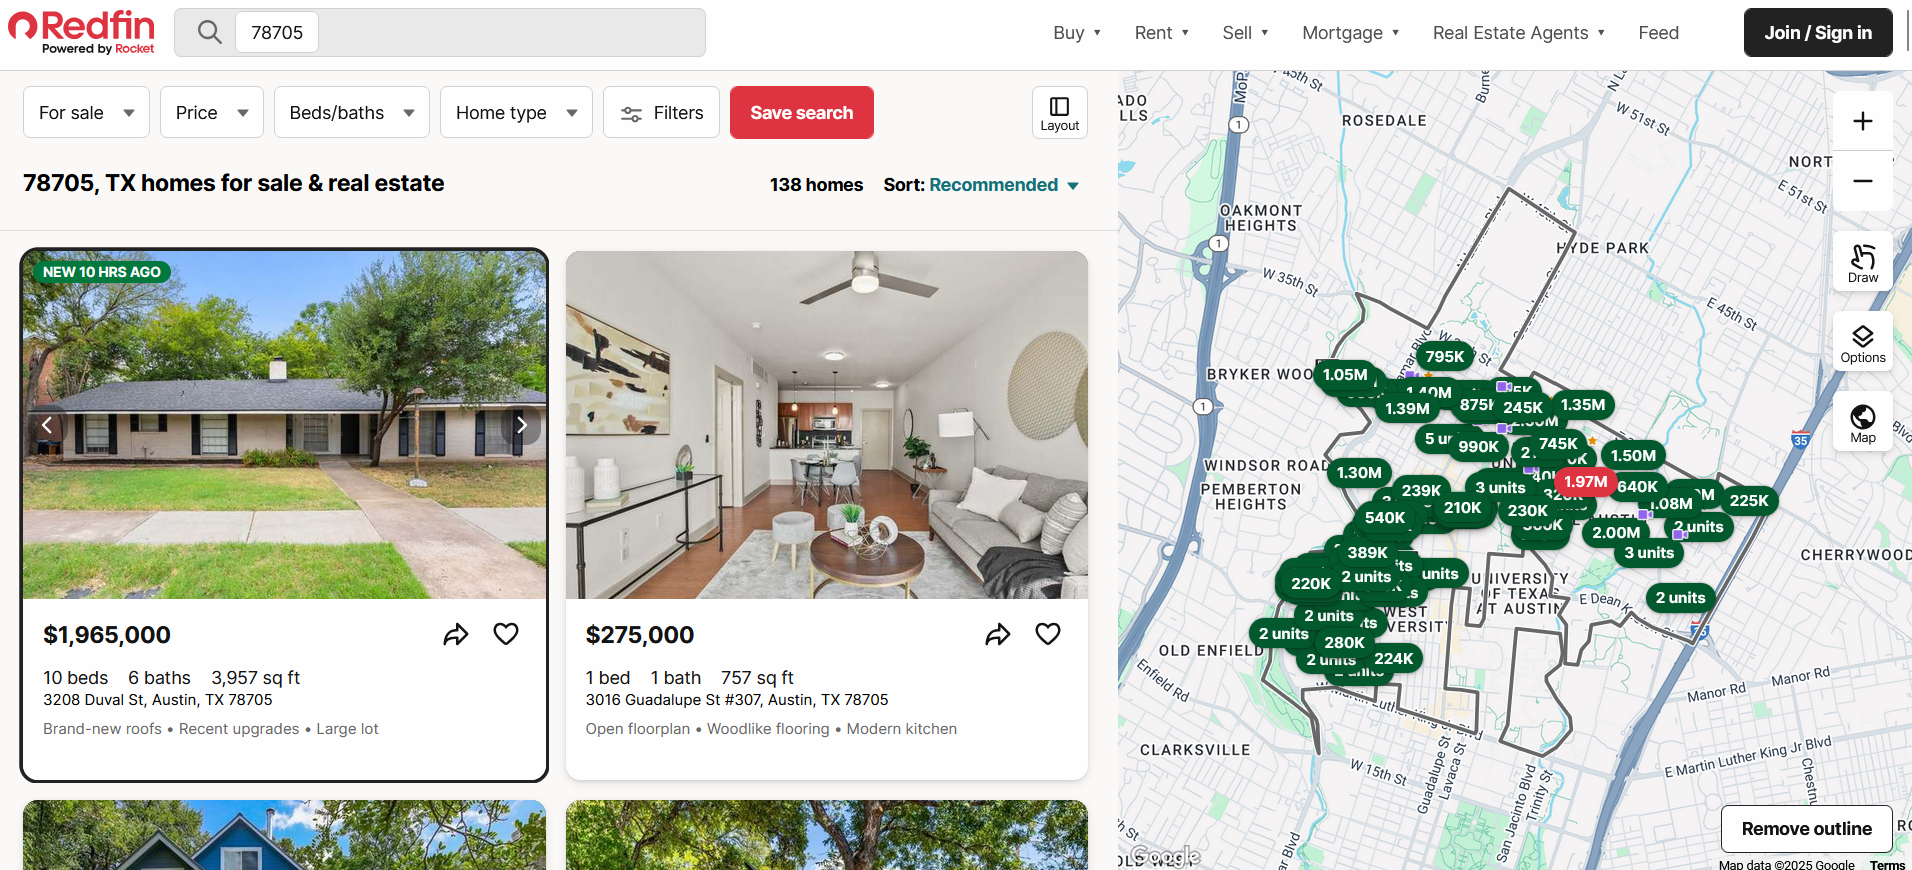


You can see next to "Sort: Recommended" that there are 138 rental properties in this search -- that would be a lot to comb through manually. So, let's send a `request` for this website address & parse it with BeautifulSoup.

In [ ]:
# Send a request to Redfin, a real estate website, to get housing information
headers = {
    # Add headers in case the system identify you as a robot
    'User-Agent': 'Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/41.0.2228.0 Safari/537.36'
}

CACHE   = 'ut_campus_rentals.html'
OFFLINE = 'redfin_78705_rentals_offline.html'   # ships with the lab
MARKER  = 'bp-Homecard__Address--address'       # the div class the listings use

# Redfin blocks automated traffic, and WHAT it sends back varies by network:
#   200 + the real page        you got through
#   202 + an EMPTY body        rate-limited (202 is a success code, so nothing raises)
#   405 / 429 + a robot page   blocked outright
# None of these raise an exception, so your selectors would just quietly find
# nothing. We therefore check for the listing marker itself rather than trusting
# the status code or the file size -- and if the live site will not talk to us,
# we fall back to a copy that ships with the lab so you can still do the work.

def looks_usable(text):
    """True only if this page actually contains rental listings."""
    return MARKER in text


html, source = None, None

# 1. Reuse a good local copy if we already have one.
if os.path.exists(CACHE):
    with open(CACHE, encoding='utf-8') as house_file:
        cached = house_file.read()
    if looks_usable(cached):
        html, source = cached, f"your saved copy ({CACHE})"

# 2. Otherwise ask Redfin. `timeout` matters: without it a blocked request can
#    hang forever, and the cell just sits at [*] printing nothing at all.
if html is None:
    try:
        response = requests.get(url="https://www.redfin.com/zipcode/78705/rentals",
                                headers=headers, timeout=60)
        print(f"Redfin answered HTTP {response.status_code} "
              f"({len(response.text):,} characters)")
        if looks_usable(response.text):
            ### "encoding='utf-8'" lets it read special characters
            with open(CACHE, 'w', encoding="utf-8") as house_file:
                house_file.write(response.text)
            html, source = response.text, "a fresh download from Redfin"
        else:
            print("  -> that response contains no listings, so Redfin is blocking "
                  "this computer.")
    except requests.exceptions.RequestException as err:
        print(f"The request to Redfin failed: {type(err).__name__}")

# 3. Fall back to the copy that ships with the lab.
if html is None and os.path.exists(OFFLINE):
    with open(OFFLINE, encoding='utf-8') as house_file:
        html = house_file.read()
    source = f"the offline copy included with the lab ({OFFLINE})"
    print("\n  Falling back to the offline copy. THIS IS FINE -- being blocked by")
    print("  Redfin is not a mistake in your code, and you are not penalised for it.")
    print("  Everything below works the same way on this copy.")

# 4. Report plainly what we ended up with.
if html is None:
    raise SystemExit(
        f"No usable page. Redfin blocked this computer and {OFFLINE} is missing "
        f"from your lab folder -- re-extract the lab ZIP and run this cell again.")

print(f"\nUsing {source}: {len(html):,} characters, listings present.")

In [ ]:
## Print out the website's HTML. It is very difficult for a human to read this!
print(html[:5000])

### We want to figure out how to read this. First, let's look at the elements of the website using the Inspector 

Right click anywhere on the web page, and click `Inspect`:

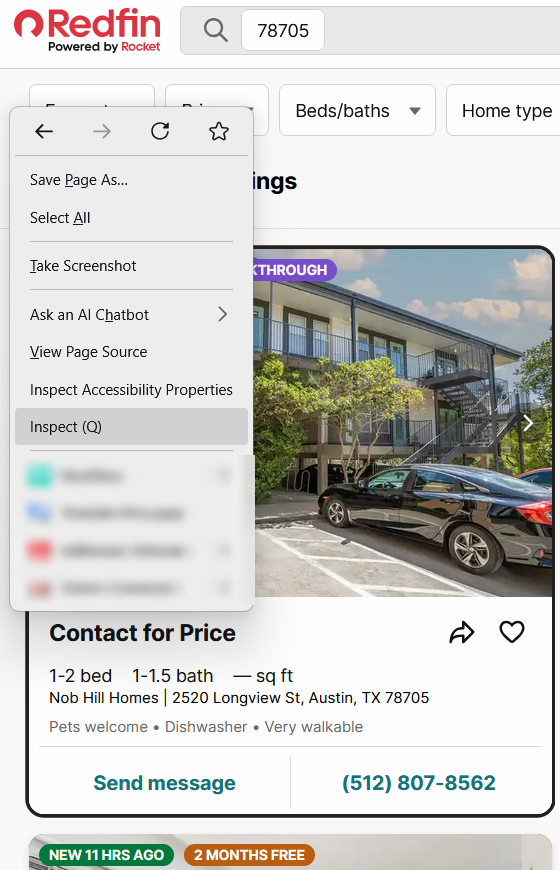

Click on the button here:

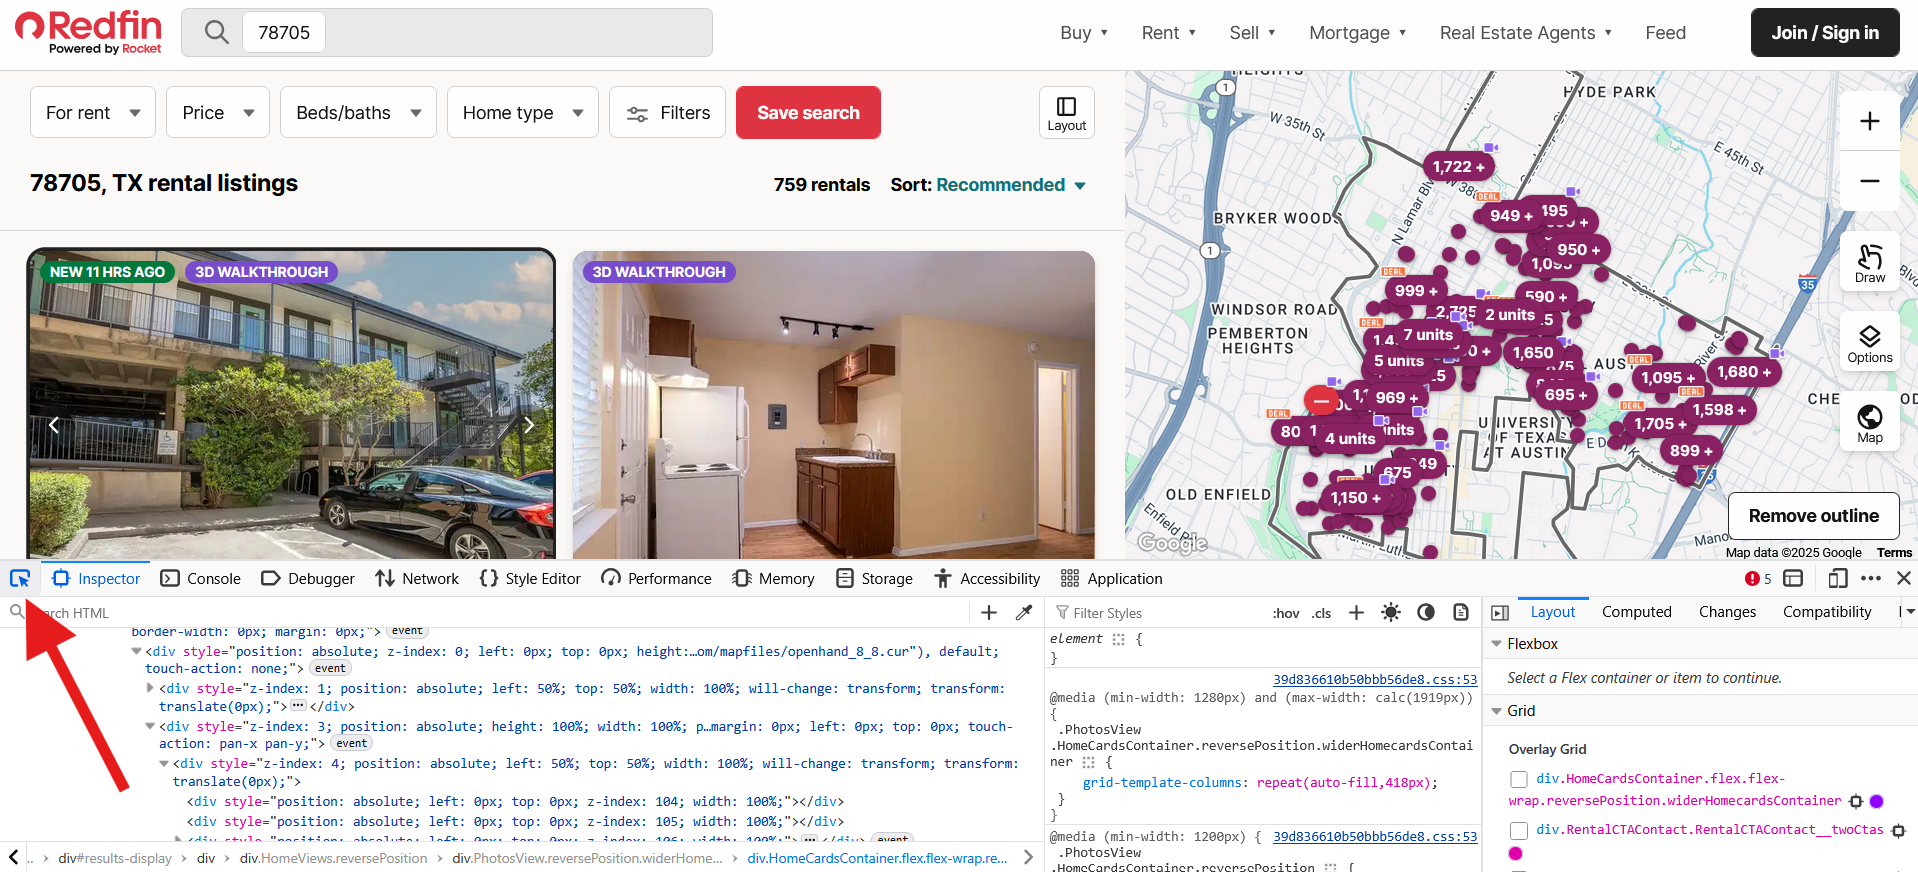

<b>You can now move your cursor around the page and see what HTML tags are associated with which elements of the webpage</b>

You can see in the bottom left panel there are many nested HTML tags & associated information. 

We can select the `<div>` tags (which stand for "divisions" of the web page) associated with a property's address:
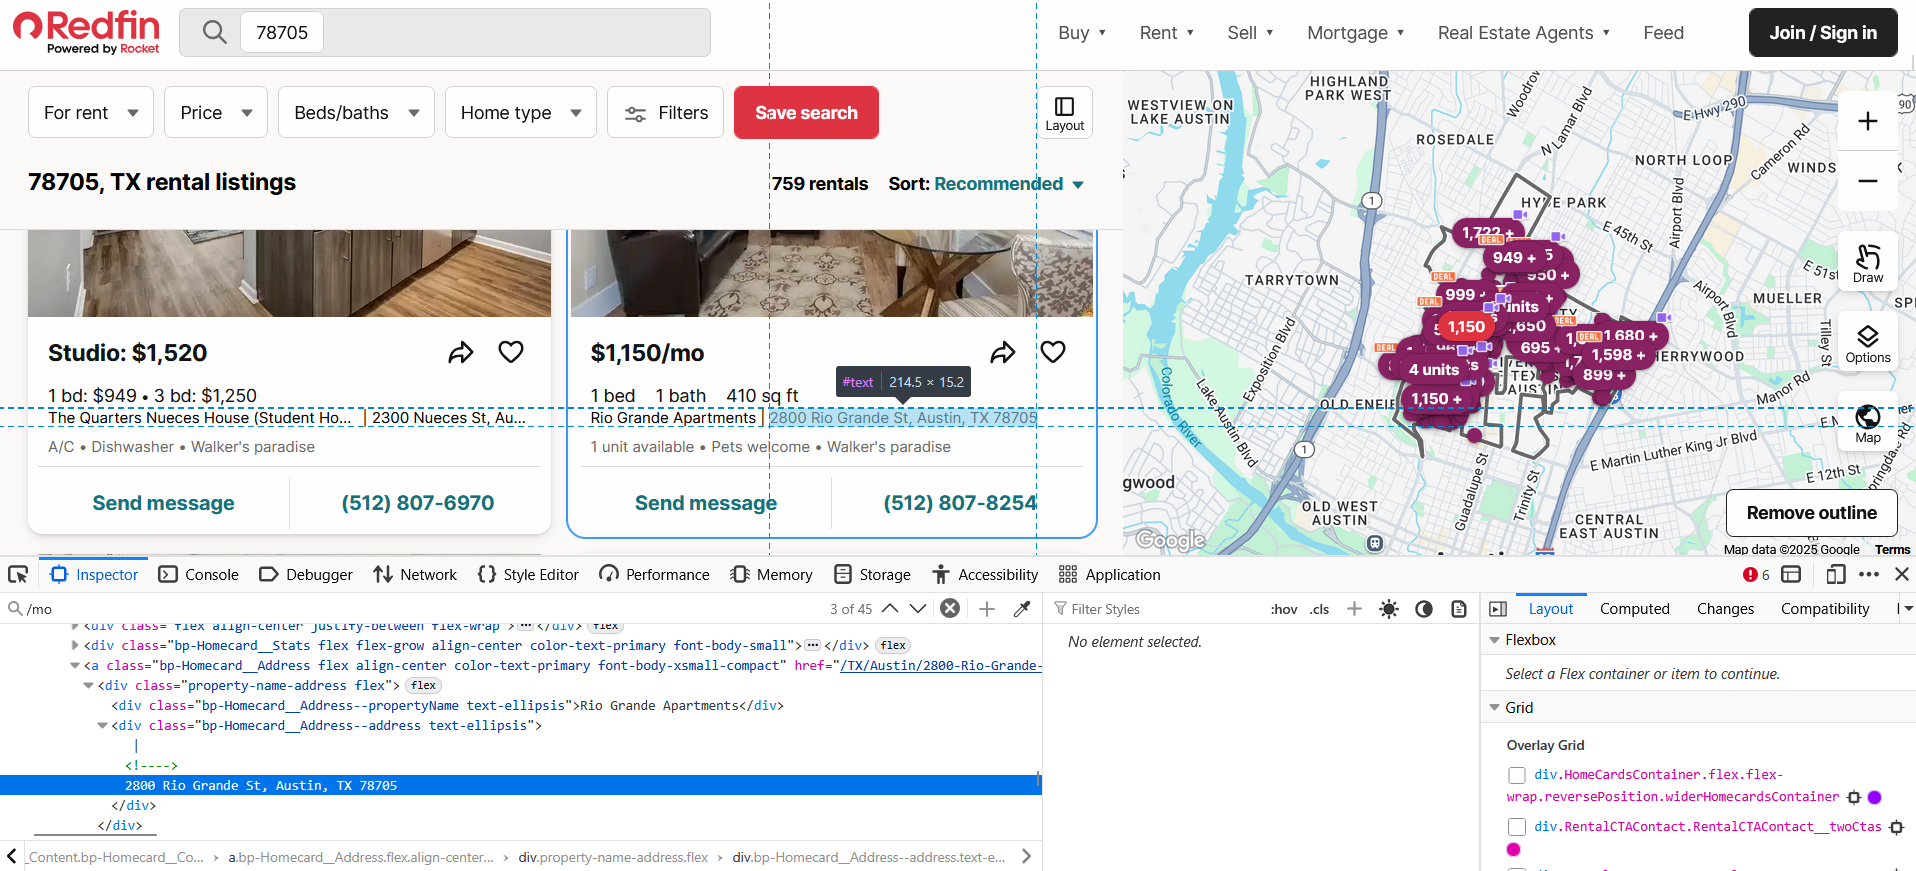

We can copy the path to the Div like so:

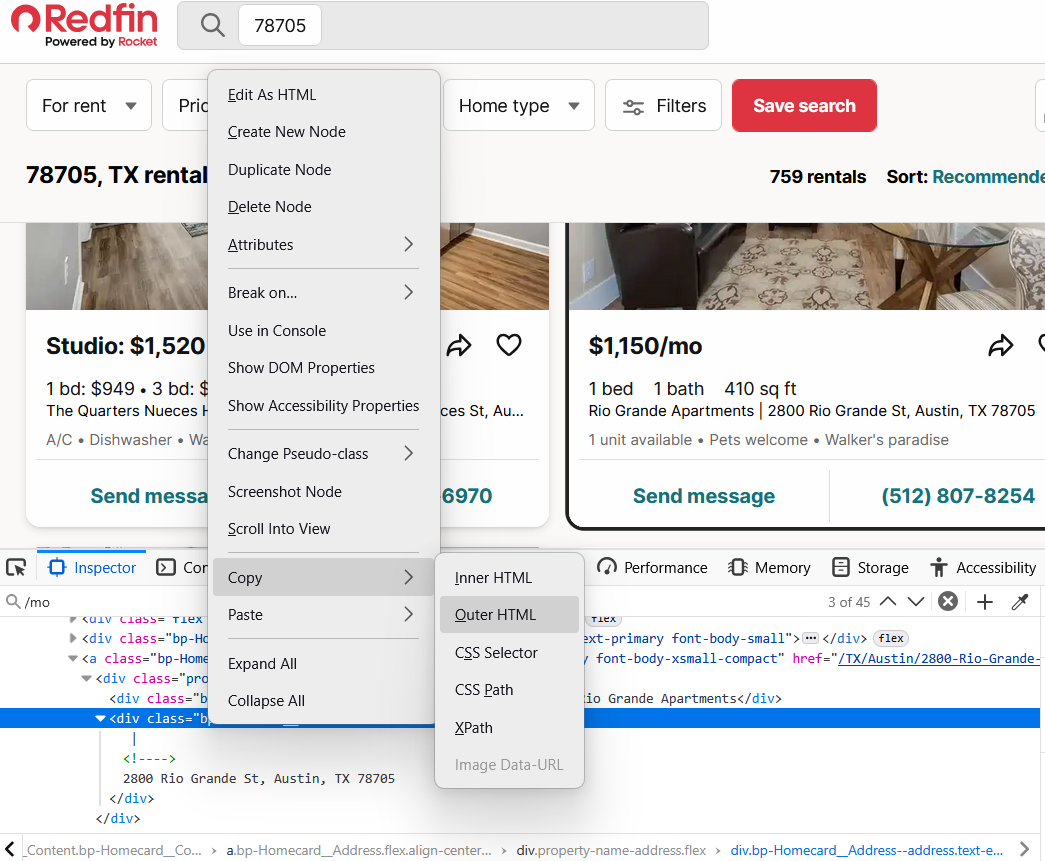

And we can see that our address is stored here:

`<div class="bp-Homecard__Address--address text-ellipsis">&nbsp;|&nbsp;<!-- -->2800 Rio Grande St, Austin, TX 78705</div>`

In [ ]:
# Let's find this using Beautiful Soup
soup = BeautifulSoup(html, 'html.parser')

In [ ]:
# You can get the Address using the Div class we found earlier
houses_addr = soup.find_all("div", class_="bp-Homecard__Address--address")

# the ".find_all() method iterates through our soup & finds each instance of the div named "bp-Homecard__Address"

# Let's just look at one of them
print(houses_addr[0])

In [ ]:
## This is still not ideal, so we'll have to add some options to our method call
# get_text(strip=True) removes blank spaces from the beginning & end of the text
# .replace("|", "") tells Python to replace every | with nothing "". 
houses_addr[0].get_text(strip=True).replace("|", "").strip()

In [ ]:
# We can see that this doesn't let us isolate the address just yet

# To get the address, we can call the .get_text() method
print(houses_addr[0].get_text())

In [ ]:
# Let's look at rent -- it's housed in a <span> tag
houses_rent = soup.find_all("span", class_="bp-Homecard__Price--value")
print(houses_rent[1])

In [ ]:
# let's say we don't want "/mo"
houses_rent[1].get_text(strip=True).replace("/mo", "").strip()

In [ ]:
# If we want to pull every price
rents=[]
for rental in houses_rent:
    rents.append(rental.get_text(strip=True).replace("/mo","").strip())
print(rents)

## <b>Exercise 3:</b>

Let's say Dr. Kang wants to collect housing data for an Austin area ZIP codes. Choose a ZIP code you actually know something about -- housing type and quality vary a lot by ZIP code, and later questions will ask you to compare the data against what you already know.

He wants a data table that contains the property name, address, prices, bedroom count, bathroom count, and <b>coordinates</b> each house in a ZIP code. Note that the coordinates will require use of the <b>Geocoding API</b>. Write your dataframe to a <.csv> file, named `ZIP-RentalData.csv` (Replace ZIP with your chosen ZIP code). Add this to an `Exercise3` folder.

As a refresher, here's the process for creating a GeoDataFrame: https://geopandas.org/en/stable/gallery/create_geopandas_from_pandas.html

He also doesn't always trust the photo on Redfin, and wants both a Google StreetView image and a remote sensing map for each.

<b>Create a `Images` sub-folder of your `Exercise3` folder.</b> Save each StreetView & map HTML to this folder. Use and f-string to ensure files are named according to the address.

---

#### Two practical notes before you start

**Work with the first 10 listings only.** A Redfin page returns about 40 rentals, and the loop you are writing is exactly the same whether it runs 10 times or 40. Slice the list so the whole class's shared API quota goes further:

```python
houses_addr = soup.find_all("div", class_="bp-Homecard__Address--address")[:10]
```

**Sanitize the address before you use it as a filename.** The text Redfin puts in
those tags often carries a leading separator, so you will get strings like
`|2810 Salado St, Austin, TX 78705`. Google's geocoder is forgiving and finds that
address anyway -- but the *filename* is a different story. `|` is an illegal
character in a Windows filename, and plenty of real addresses contain a slash
(`76 1/2 Rainey St`), which Python reads as a folder that does not exist. Either
one will crash your save step partway through the loop.

Clean the text once, then build the filename from the clean version:

```python
address = tag.get_text(strip=True).lstrip("|").strip()
safe_name = "".join(ch for ch in address if ch.isalnum() or ch in " ,.-").strip()
img_path = f"Exercise3/Images/{safe_name}.jpg"
```

Build your loop so it makes <b>one</b> geocode and <b>one</b> Street View request per property. If you find yourself with a Street View loop inside a geocoding loop, you are making 10 x 10 requests instead of 10 + 10, and the call guard will stop you.

Call `calls_used()` at any point to see how much of the budget you have spent.

**One more trap, and it is the one most likely to waste your evening.** Redfin
rate-limits scrapers by answering with **HTTP 202 and an empty body** instead of
an error. 202 is a *success* code, so `response.raise_for_status()` will not
catch it, and your selectors will simply find nothing on a page that is not
there. If `find_all` suddenly returns 0 listings on code that worked five minutes
ago, you are being throttled -- wait a few minutes, and never put the Redfin
request itself inside your loop. Fetch the page once, then loop over the result.

---

#### If Redfin blocks you

Redfin refuses automated traffic from some networks, and what it sends back varies:
HTTP **202 with an empty body**, **405**, or **429** with an "Are You a Robot?" page.
None of these raise a Python error, so your loop would simply find nothing.

**This is not a mistake in your code and it does not cost you any credit.**

First, just try again — the block is usually temporary and often clears on the second
attempt a minute later. If it does not, this lab ships an offline copy of several
Austin ZIP codes. Pick one of these and you can do the whole exercise offline:

| ZIP | listings with both an address and a price |
|---|---|
| **78705** (UT campus) | 37 |
| **78745** (south Austin) | 36 |
| **78741** (east Riverside) | 35 |
| 78723 (Mueller / east) | 25 |
| 78748 (far south) | 20 |

```python
ZIP_CODE = "78745"          # any ZIP from the table above
with open(f"redfin_{ZIP_CODE}_rentals_offline.html", encoding="utf-8") as f:
    soup = BeautifulSoup(f.read(), "html.parser")
```

These files contain the same listing markup the live site returns, so every selector
you just learned works on them unchanged.

**A note on what you will find.** Not every listing has every field. Apartment
complexes are often listed by name with no street address, and some have no price.
That is real data, not a bug — pull each field from inside its own card and let the
missing ones be `None`, rather than building parallel lists and zipping them
together. Say in a comment which ZIP you used and whether you worked offline.

In [ ]:
# =====================================================================
# STEP 0 -- FOLDERS AND THE SAVE HELPER.  Written for you. Just run it.
#
# Two pieces of plumbing that are not what this exercise is testing:
#   * making the output folders
#   * turning your finished table into a GeoDataFrame and writing the .csv
#
# Your job is the scraping and the geocoding. Collect each house as a plain
# dictionary, append it to a list, then hand that list to save_rental_table().
# =====================================================================

os.makedirs("Exercise3/Images", exist_ok=True)
print("created Exercise3/ and Exercise3/Images/")


def save_rental_table(records, zip_code, folder="Exercise3"):
    """Turn your list of house dictionaries into a GeoDataFrame and save it.

    records -- a list of dicts, each with at least:
                 name, address, price, beds, baths, lat, lon
               (lat / lon come from geocode(), which you used in Exercise 2)
    zip_code -- the ZIP you chose, e.g. "78704"

    Returns the GeoDataFrame so you can look at it or map it.
    """
    df = pd.DataFrame(records)

    missing = {"lat", "lon"} - set(df.columns)
    if missing:
        raise ValueError(f"records are missing {missing} -- geocode before saving")

    # this is the pandas -> GeoPandas step the exercise links to:
    gdf = gpd.GeoDataFrame(
        df,
        geometry=gpd.points_from_xy(df["lon"], df["lat"]),   # note: lon first, then lat
        crs="EPSG:4326",
    )

    out_path = os.path.join(folder, f"{zip_code}-RentalData.csv")
    gdf.to_csv(out_path, index=False)
    print(f"wrote {len(gdf)} rows to {out_path}")
    return gdf


# ---- example of the shape save_rental_table() expects (not real data) -------
# houses = []
# houses.append({"name": "Some Apartments", "address": "123 S 1st St, Austin, TX",
#                "price": "1850", "beds": "2", "baths": "1", "lat": 30.25, "lon": -97.75})
# rentals = save_rental_table(houses, "78704")

In [ ]:
## Exercise 3 here


# <b>Deliverables</b>

## 1. Submit a `Lab3_Exercises.zip` file that contains the following:
#### - `Exercise1_HTML` folder
#### - `Exercise2_Images` folder
#### - `Exercise3` folder with its `Images` subfolder
#### Do **not** include the `api_cache` folder in your ZIP.
That folder is the notebook's saved copies of its API replies. It is there for *you* — it is why re-running a cell costs nothing — but it is not part of your submission and it makes the upload much larger. Leave it on your computer: if you come back and re-run the lab, it saves the whole class's shared API quota.
## 2. Submit your Lab 3 notebook as an `.ipynb` file, with every cell run.
#### (The `Exercise1_HTML` folder above is the *scraped web pages* from Exercise 1 — that is different from exporting the notebook, and it is still required.)